In [7]:
import pandas as pd
import numpy as np

satıs_sayisi = 300

categories = ["Elektronik", "Giyim", "Kitap", "Kozmetik", "Ev"]
cities = ["İstanbul", "Ankara", "İzmir", "Bursa", "Antalya"]
payment_types = ["Kredi Kartı", "Kapıda Ödeme", "Havale/EFT"]
products = ["Laptop", "Tişört", "Roman", "Parfüm", "Tava", "Kulaklık", "Pantolon", "Defter", "Ruj", "Lamba"]

veri = {
    "OrderId": range(1, satıs_sayisi + 1),
    "Product": np.random.choice(products, satıs_sayisi),
    "Category": np.random.choice(categories, satıs_sayisi),
    "Price": np.random.randint(50, 5000, satıs_sayisi),
    "Quantity": np.random.randint(1, 6, satıs_sayisi),
    "CustomerAge": np.random.randint(18, 70, satıs_sayisi),
    "City": np.random.choice(cities, satıs_sayisi),
    "PaymentType": np.random.choice(payment_types, satıs_sayisi)
}

df = pd.DataFrame(veri)
df.to_csv("ecommerce_sales.csv", index=False)

In [8]:
df.head()

,OrderId,Product,Category,Price,Quantity,CustomerAge,City,PaymentType
0,1,Tişört,Kitap,4914,5,18,Ankara,Kredi Kartı
1,2,Kulaklık,Ev,2407,4,54,İstanbul,Kapıda Ödeme
2,3,Tişört,Kitap,3870,5,27,İstanbul,Kredi Kartı
3,4,Tişört,Giyim,1566,1,52,Antalya,Kapıda Ödeme
4,5,Parfüm,Kitap,1202,4,39,Antalya,Kredi Kartı


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   OrderId      300 non-null    int64
 1   Product      300 non-null    str  
 2   Category     300 non-null    str  
 3   Price        300 non-null    int32
 4   Quantity     300 non-null    int32
 5   CustomerAge  300 non-null    int32
 6   City         300 non-null    str  
 7   PaymentType  300 non-null    str  
dtypes: int32(3), int64(1), str(4)
memory usage: 15.4 KB


In [25]:
df = pd.read_csv("ecommerce_sales.csv")

toplam_siparis = df.shape[0]
toplam_urun_miktari = df["Quantity"].sum()
ortalama_fiyat = df["Price"].mean()
en_pahali = df["Price"].max()
en_ucuz = df["Price"].min()

print("--- E-Ticaret Satış Temel İstatistikleri ---")
print(f"Toplam Sipariş Sayısı     : {toplam_siparis}")
print(f"Satılan Toplam Ürün Adedi : {toplam_urun_miktari}")
print(f"Ortalama Ürün Fiyatı      : {ortalama_fiyat:.2f} TL")
print(f"En Pahalı Ürün Fiyatı     : {en_pahali} TL")
print(f"En Ucuz Ürün Fiyatı       : {en_ucuz} TL")

--- E-Ticaret Satış Temel İstatistikleri ---
Toplam Sipariş Sayısı     : 300
Satılan Toplam Ürün Adedi : 908
Ortalama Ürün Fiyatı      : 2679.06 TL
En Pahalı Ürün Fiyatı     : 4996 TL
En Ucuz Ürün Fiyatı       : 101 TL


In [27]:
df["TotalPrice"] = df["Price"] * df["Quantity"]

def yas_grubu(age):
    if age <= 25:
        return "Genç"
    elif age <= 40:
        return "Yetişkin"
    elif age <= 60:
        return "Orta Yaş"
    else:
        return "60+"

df["AgeGroup"] = df["CustomerAge"].apply(yas_grubu)

In [28]:
df.head()

,OrderId,Product,Category,Price,Quantity,CustomerAge,City,PaymentType,TotalPrice,AgeGroup
0,1,Tişört,Kitap,4914,5,18,Ankara,Kredi Kartı,24570,Genç
1,2,Kulaklık,Ev,2407,4,54,İstanbul,Kapıda Ödeme,9628,Orta Yaş
2,3,Tişört,Kitap,3870,5,27,İstanbul,Kredi Kartı,19350,Yetişkin
3,4,Tişört,Giyim,1566,1,52,Antalya,Kapıda Ödeme,1566,Orta Yaş
4,5,Parfüm,Kitap,1202,4,39,Antalya,Kredi Kartı,4808,Yetişkin


In [39]:
print("--- 1. En Fazla Gelir Getiren Kategori ---")
print(df.groupby('Category')['TotalPrice'].sum())

print("\n--- 2. En Fazla Satılan Ürün ---")
print(df.groupby('Product')['Quantity'].sum())

print("\n--- 3. Şehirlere Göre Toplam Satış ---")
print(df.groupby('City')['TotalPrice'].sum())

print("\n--- 4. Ödeme Yöntemlerine Göre Sipariş Sayısı ---")
print(df.groupby('PaymentType')['OrderId'].count())

print("\n--- 5. Yaş Gruplarına Göre Harcama Miktarı ---")
print(df.groupby('AgeGroup')['TotalPrice'].sum())


--- 1. En Fazla Gelir Getiren Kategori ---
Category
Elektronik    534188
Ev            638082
Giyim         509891
Kitap         409725
Kozmetik      350926
Name: TotalPrice, dtype: int64

--- 2. En Fazla Satılan Ürün ---
Product
Defter      109
Kulaklık    107
Lamba        64
Laptop       83
Pantolon     93
Parfüm       91
Roman        88
Ruj         109
Tava         94
Tişört       70
Name: Quantity, dtype: int64

--- 3. Şehirlere Göre Toplam Satış ---
City
Ankara      494010
Antalya     502270
Bursa       443064
İstanbul    529911
İzmir       473557
Name: TotalPrice, dtype: int64

--- 4. Ödeme Yöntemlerine Göre Sipariş Sayısı ---
PaymentType
Havale/EFT       94
Kapıda Ödeme     95
Kredi Kartı     111
Name: OrderId, dtype: int64

--- 5. Yaş Gruplarına Göre Harcama Miktarı ---
AgeGroup
60+          313864
Genç         403951
Orta Yaş    1026685
Yetişkin     698312
Name: TotalPrice, dtype: int64


In [40]:
df.sort_values(by="TotalPrice", ascending=False).head(10)

,OrderId,Product,Category,Price,Quantity,CustomerAge,City,PaymentType,TotalPrice,AgeGroup
105,106,Defter,Giyim,4985,5,62,Ankara,Havale/EFT,24925,60+
288,289,Laptop,Giyim,4953,5,69,Antalya,Kapıda Ödeme,24765,60+
0,1,Tişört,Kitap,4914,5,18,Ankara,Kredi Kartı,24570,Genç
96,97,Roman,Ev,4783,5,41,İzmir,Kredi Kartı,23915,Orta Yaş
123,124,Laptop,Ev,4753,5,45,İstanbul,Kredi Kartı,23765,Orta Yaş
129,130,Lamba,Ev,4659,5,42,İzmir,Kredi Kartı,23295,Orta Yaş
76,77,Parfüm,Ev,4657,5,54,Antalya,Kredi Kartı,23285,Orta Yaş
170,171,Kulaklık,Ev,4638,5,38,Bursa,Kapıda Ödeme,23190,Yetişkin
252,253,Laptop,Ev,4630,5,43,Bursa,Kredi Kartı,23150,Orta Yaş
140,141,Defter,Giyim,4613,5,60,Bursa,Kredi Kartı,23065,Orta Yaş


C:\Users\MyComputer\AppData\Local\Temp\ipykernel_19024\746131496.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=kategori_gelir, x='Category', y='TotalPrice', palette='viridis')
C:\Users\MyComputer\AppData\Local\Temp\ipykernel_19024\746131496.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sehir_satis, x='City', y='TotalPrice', palette='magma')
C:\Users\MyComputer\AppData\Local\Temp\ipykernel_19024\746131496.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='PaymentType', palette='Set2')


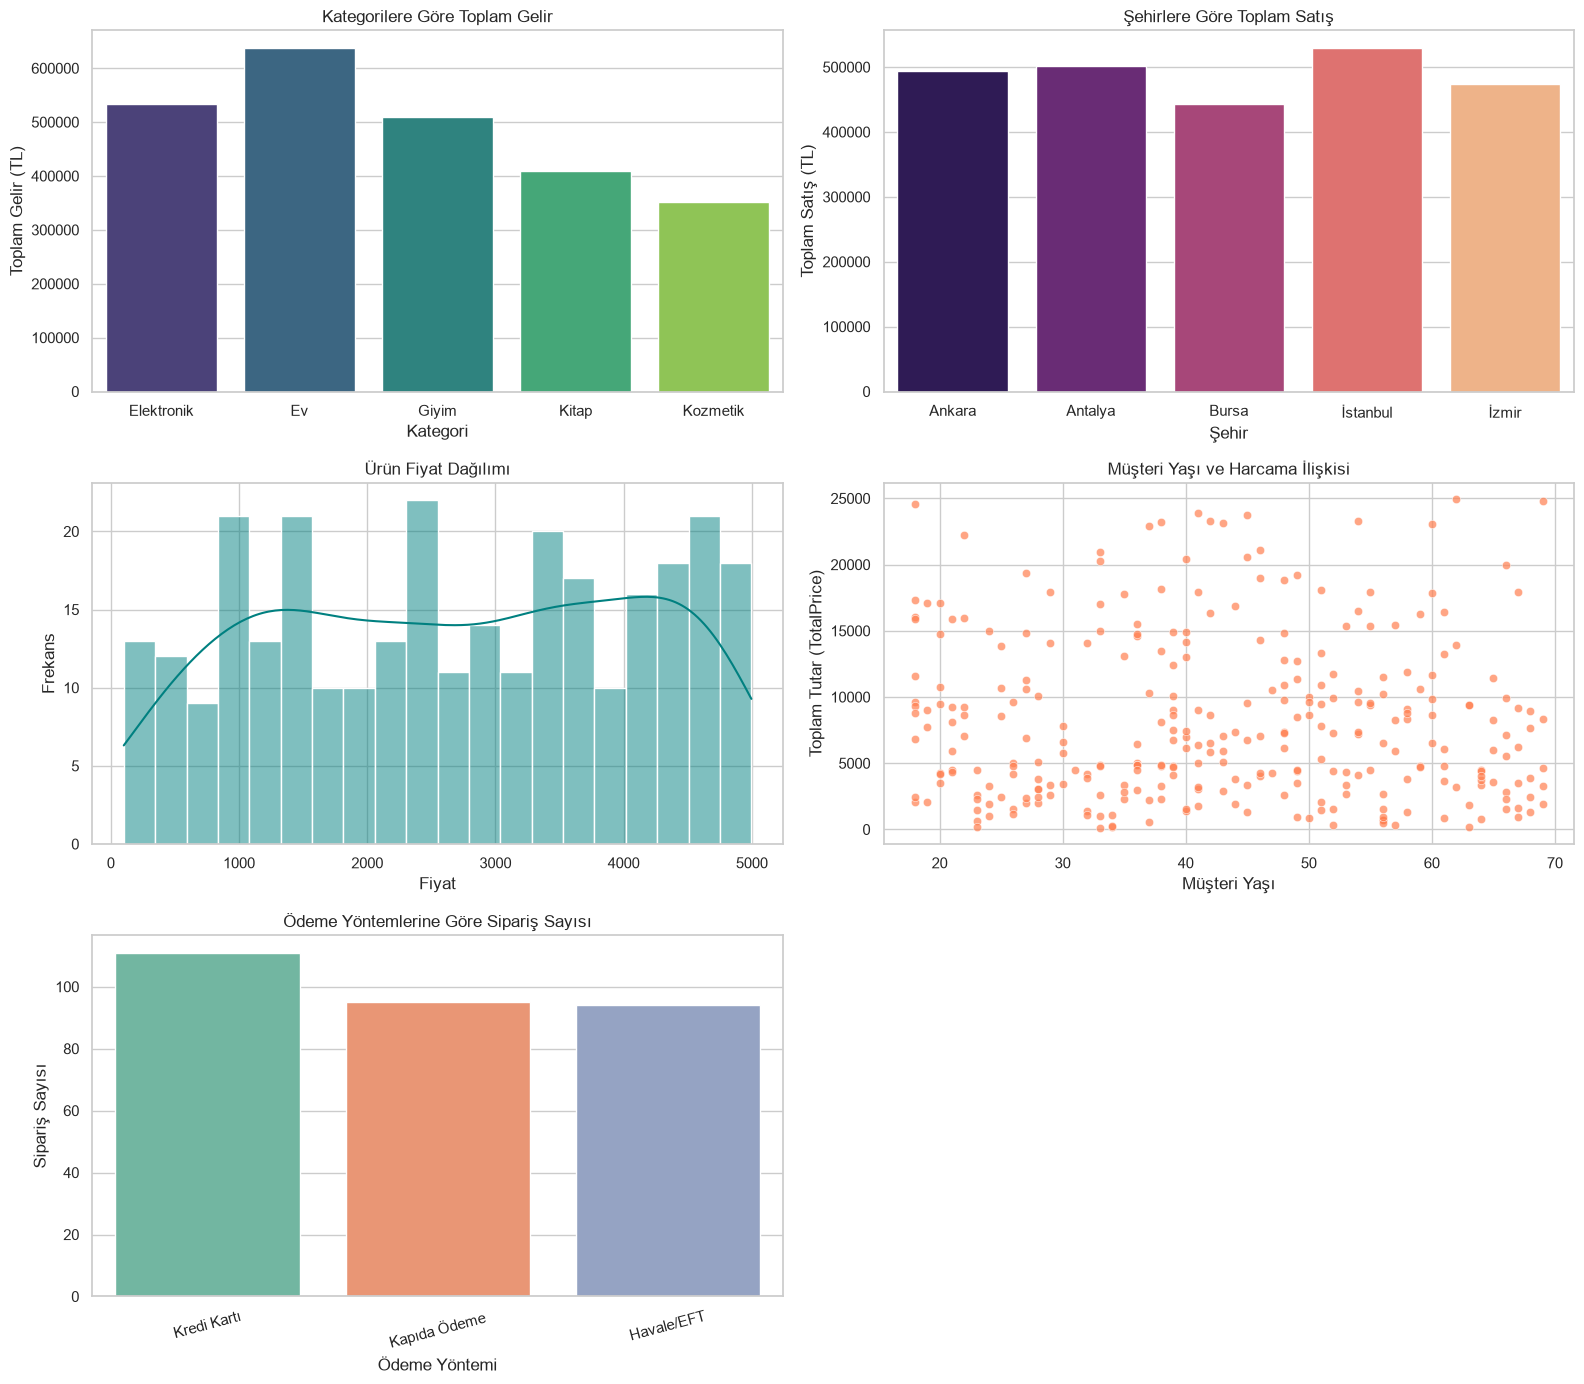

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 14))

plt.subplot(3, 2, 1)
kategori_gelir = df.groupby('Category')['TotalPrice'].sum().reset_index()
sns.barplot(data=kategori_gelir, x='Category', y='TotalPrice', palette='viridis')
plt.title('Kategorilere Göre Toplam Gelir')
plt.xlabel('Kategori')
plt.ylabel('Toplam Gelir (TL)')

plt.subplot(3, 2, 2)
sehir_satis = df.groupby('City')['TotalPrice'].sum().reset_index()
sns.barplot(data=sehir_satis, x='City', y='TotalPrice', palette='magma')
plt.title('Şehirlere Göre Toplam Satış')
plt.xlabel('Şehir')
plt.ylabel('Toplam Satış (TL)')

plt.subplot(3, 2, 3)
sns.histplot(df['Price'], bins=20, kde=True, color='teal')
plt.title('Ürün Fiyat Dağılımı')
plt.xlabel('Fiyat')
plt.ylabel('Frekans')

plt.subplot(3, 2, 4)
sns.scatterplot(data=df, x='CustomerAge', y='TotalPrice', alpha=0.7, color='coral')
plt.title('Müşteri Yaşı ve Harcama İlişkisi')
plt.xlabel('Müşteri Yaşı')
plt.ylabel('Toplam Tutar (TotalPrice)')

plt.subplot(3, 2, 5)
sns.countplot(data=df, x='PaymentType', palette='Set2')
plt.title('Ödeme Yöntemlerine Göre Sipariş Sayısı')
plt.xlabel('Ödeme Yöntemi')
plt.ylabel('Sipariş Sayısı')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [46]:
import sqlite3

conn = sqlite3.connect("ecommerce.db")
df.to_sql("orders", conn, if_exists="replace", index=False)

query = """
SELECT Category, SUM(TotalPrice) as TotalRevenue
FROM orders
GROUP BY Category
"""

sql_result = pd.read_sql(query, conn)
print(sql_result)
print("-" * 40)

query_order = """
SELECT OrderId, Product, City, TotalPrice
FROM orders
WHERE City = 'İstanbul'
ORDER BY TotalPrice DESC
LIMIT 5
"""
print(pd.read_sql(query_order, conn))
conn.close()


     Category  TotalRevenue
0  Elektronik        534188
1          Ev        638082
2       Giyim        509891
3       Kitap        409725
4    Kozmetik        350926
----------------------------------------
   OrderId   Product      City  TotalPrice
0      124    Laptop  İstanbul       23765
1       15  Kulaklık  İstanbul       20930
2      229    Laptop  İstanbul       20555
3        3    Tişört  İstanbul       19350
4      268    Tişört  İstanbul       18148
